# Practical 8: Decision Tree Classifier

**Dataset:** Breast Cancer Wisconsin (569 samples, 30 features, target: malignant or benign)

**Aim:** Build decision trees with entropy and Gini, compare depths, find the best root node using information gain and visualize the tree.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
print(X.shape)
print(y.map({0: "malignant", 1: "benign"}).value_counts())
X.head()

(569, 30)
target
benign       357
malignant    212
Name: count, dtype: int64


   mean radius  mean texture  ...  worst symmetry  worst fractal dimension
0        17.99         10.38  ...          0.4601                  0.11890
1        20.57         17.77  ...          0.2750                  0.08902
2        19.69         21.25  ...          0.3613                  0.08758
3        11.42         20.38  ...          0.6638                  0.17300
4        20.29         14.34  ...          0.2364                  0.07678

[5 rows x 30 columns]

**Result:** The data has 569 samples and 30 numeric features with no missing values. There are 212 malignant and 357 benign cases, so the classes are reasonably balanced.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (455, 30)
Test : (114, 30)


**Result:** The data was split 80 percent for training (455 samples) and 20 percent for testing (114 samples).

In [3]:
records = []
for rule in ["entropy", "gini"]:
    for depth in [2, 3, 4, 5, 6, None]:
        model = DecisionTreeClassifier(criterion=rule, max_depth=depth, random_state=42).fit(X_train, y_train)
        records.append([rule, "full" if depth is None else depth,
                        round(accuracy_score(y_train, model.predict(X_train)), 3),
                        round(accuracy_score(y_test, model.predict(X_test)), 3)])
comparison = pd.DataFrame(records, columns=["Criterion", "Max depth", "Train accuracy", "Test accuracy"])
print(comparison)

   Criterion Max depth  Train accuracy  Test accuracy
0    entropy         2           0.958          0.895
1    entropy         3           0.967          0.947
2    entropy         4           0.985          0.939
3    entropy         5           0.991          0.930
4    entropy         6           1.000          0.912
5    entropy      full           1.000          0.912
6       gini         2           0.958          0.895
7       gini         3           0.976          0.939
8       gini         4           0.987          0.939
9       gini         5           0.993          0.921
10      gini         6           0.998          0.912
11      gini      full           1.000          0.912


**Result:** Training accuracy rises with depth and reaches 1.0 for the full tree, while test accuracy does not keep rising. This shows that very deep trees overfit.

In [4]:
best = comparison.loc[comparison["Test accuracy"].idxmax()]
best_rule = best["Criterion"]
best_depth = None if best["Max depth"] == "full" else int(best["Max depth"])
tree = DecisionTreeClassifier(criterion=best_rule, max_depth=best_depth, random_state=42).fit(X_train, y_train)
pred = tree.predict(X_test)
print("Chosen model:", best_rule, "with max depth", best_depth)
print("Test accuracy:", round(accuracy_score(y_test, pred), 4))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=raw.target_names))

Chosen model: entropy with max depth 3
Test accuracy: 0.9474
[[38  4]
 [ 2 70]]
              precision    recall  f1-score   support

   malignant       0.95      0.90      0.93        42
      benign       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



**Result:** The chosen model uses entropy with maximum depth 3 and gets 94.74% accuracy on unseen data. The confusion matrix shows how many malignant and benign cases were predicted correctly.

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 38.60
|   |   |   |--- class: 1
|   |   |--- area error >  38.60
|   |   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- mean texture <= 20.30
|   |   |   |--- class: 1
|   |   |--- mean texture >  20.30
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



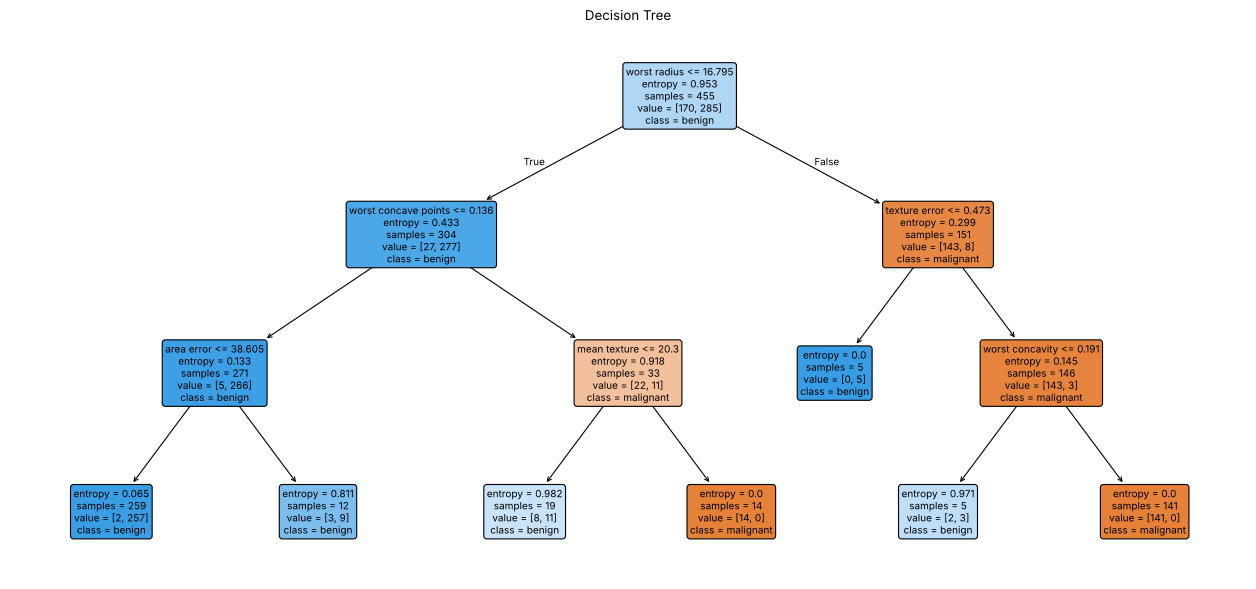

In [5]:
plt.figure(figsize=(20, 9))
plot_tree(tree, feature_names=list(X.columns), class_names=list(raw.target_names), filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree")
plt.show()
print(export_text(tree, feature_names=list(X.columns)))

**Result:** The tree diagram and the text rules show the questions asked at each node, starting from the root. Darker colours show purer nodes.

worst radius            0.6704
worst concave points    0.1700
texture error           0.0627
worst concavity         0.0423
mean texture            0.0304
area error              0.0243
mean compactness        0.0000
mean smoothness         0.0000
dtype: float64


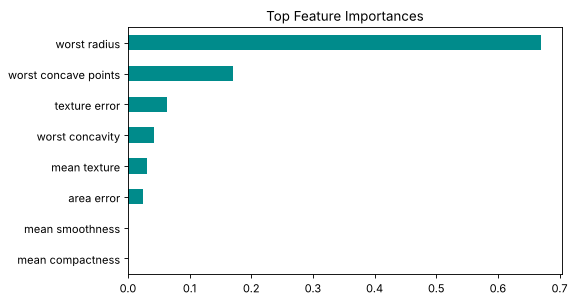

In [6]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importance.head(8)
print(top.round(4))
top.sort_values().plot(kind="barh", figsize=(7, 4), color="darkcyan")
plt.title("Top Feature Importances")
plt.show()

**Result:** The most important feature is worst radius with importance 0.6704.

### Best root node using entropy and information gain

In [7]:
def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def gini(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - (p ** 2).sum()

def best_cut(values, labels):
    order = np.argsort(values)
    v, l = values[order], labels[order]
    cuts = (v[1:] + v[:-1]) / 2
    top_gain, top_cut = 0, None
    for c in np.unique(cuts):
        left, right = l[v <= c], l[v > c]
        if len(left) == 0 or len(right) == 0:
            continue
        w = len(left) / len(l)
        gain = entropy(l) - (w * entropy(left) + (1 - w) * entropy(right))
        if gain > top_gain:
            top_gain, top_cut = gain, c
    return top_gain, top_cut

yt = y_train.to_numpy()
rows = []
for col in X_train.columns:
    g, c = best_cut(X_train[col].to_numpy(), yt)
    rows.append([col, round(c, 4), round(g, 4)])
gain_table = pd.DataFrame(rows, columns=["Feature", "Best threshold", "Information gain"]).sort_values("Information gain", ascending=False).reset_index(drop=True)
print("Parent entropy:", round(entropy(yt), 4))
print("Parent Gini   :", round(gini(yt), 4))
print(gain_table.head(8))

Parent entropy: 0.9534
Parent Gini   : 0.4681
                Feature  Best threshold  Information gain
0          worst radius         16.7950            0.5652
1       worst perimeter        106.1000            0.5641
2            worst area        884.7500            0.5547
3  worst concave points          0.1455            0.5523
4   mean concave points          0.0492            0.5489
5             mean area        696.2500            0.4780
6        mean perimeter         98.8250            0.4780
7           mean radius         15.0450            0.4717


Root from sklearn   : worst radius <= 16.795
Root from calculation: worst radius <= 16.795


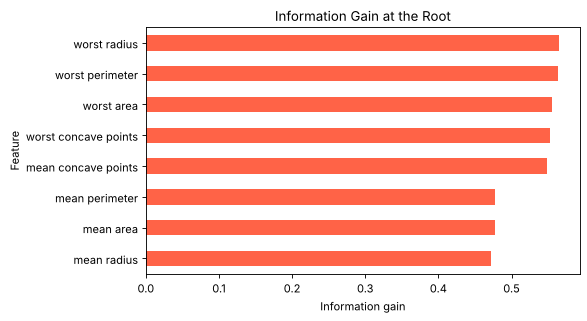

In [8]:
root_model = DecisionTreeClassifier(criterion="entropy", random_state=42).fit(X_train, y_train)
sk_feature = X.columns[root_model.tree_.feature[0]]
sk_cut = root_model.tree_.threshold[0]
my_feature = gain_table.loc[0, "Feature"]
my_cut = gain_table.loc[0, "Best threshold"]
print("Root from sklearn   :", sk_feature, "<=", round(sk_cut, 4))
print("Root from calculation:", my_feature, "<=", my_cut)
gain_table.head(8).set_index("Feature")["Information gain"].sort_values().plot(kind="barh", figsize=(7, 4), color="tomato")
plt.title("Information Gain at the Root")
plt.xlabel("Information gain")
plt.show()

**Result:** The best root node is **worst radius <= 16.795** with the highest information gain of 0.5652. It is the same split that sklearn selects, which confirms the calculation.

In [9]:
col, cut = my_feature, my_cut
mask = X_train[col].to_numpy() <= cut
left, right = yt[mask], yt[~mask]
w = len(left) / len(yt)
child_entropy = w * entropy(left) + (1 - w) * entropy(right)
child_gini = w * gini(left) + (1 - w) * gini(right)
print("Split        :", col, "<=", cut)
print("Left node    : n =", len(left), "entropy =", round(entropy(left), 4), "gini =", round(gini(left), 4))
print("Right node   : n =", len(right), "entropy =", round(entropy(right), 4), "gini =", round(gini(right), 4))
print("Information gain =", round(entropy(yt), 4), "-", round(child_entropy, 4), "=", round(entropy(yt) - child_entropy, 4))
print("Gini reduction   =", round(gini(yt), 4), "-", round(child_gini, 4), "=", round(gini(yt) - child_gini, 4))

Split        : worst radius <= 16.795
Left node    : n = 304 entropy = 0.4325 gini = 0.1619
Right node   : n = 151 entropy = 0.2989 gini = 0.1003
Information gain = 0.9534 - 0.3882 = 0.5652
Gini reduction   = 0.4681 - 0.1414 = 0.3266


**Result:** Splitting on worst radius reduces entropy from 0.9534 to 0.3882 and Gini from 0.4681 to 0.1414. Both measures drop the most for this feature, so it is the best root node.